# 01 — Established functional-inference benchmarking metrics

This notebook consolidates the established PICRUSt/PICRUSt2 profile benchmark and the published
Matchado/Sun biological-group metric families for **PICRUSt2**, **PICRUSt2 + adaptation** (the cached
basic-MLP `picrust2_teacher_only_residual` arm), and **Tax4Fun2**. It covers the complete accepted surface:

- 23 independent biological outer groups, 26 study strata, and 1,639 paired samples;
- **11 benchmark strata plus 15 expansion strata** (not 15 studies total);
- 10 pre-audited biological contrasts where labels/phenotypes exist.

No training, LOSO fitting, raw-read processing, or model selection occurs here. Numerical metrics
are recomputed from the accepted sample/per-KO evaluation tables produced from frozen WGS and cached
predictions. The source files remain read-only.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
DATA = ROOT / "data"
STUDIES = DATA / "studies"
REFERENCE = DATA / "reference"
ANALYSIS = REFERENCE
FIGREF = REFERENCE
CONTRACT = REFERENCE
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
from picrust_benchmark_metrics import (
    plot_directional_metric_summary,
    plot_directional_roc_grid,
    plot_ko_coverage,
    plot_matchado_randomization_dumbbells,
    plot_method_differences,
    plot_metric_row_grid,
    plot_profile_study_panels,
    plot_signed_decile_grid,
    plot_stratum_mean_ranges,
    plot_sun_observed_controls,
)
sns.set_theme(style="whitegrid", context="notebook")
METHODS = ["PICRUSt2", "PICRUSt2 + adaptation"]
COLORS = {"PICRUSt2": "#4C78A8", "PICRUSt2 + adaptation": "#E45756"}
COLORS["Tax4Fun2"] = "#F2A900"
assert STUDIES.is_dir() and REFERENCE.is_dir(), "Run from a complete repository checkout"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

METHODS = ["PICRUSt2", "PICRUSt2 + adaptation", "Tax4Fun2"]

## Provenance and accepted surfaces

The exact reference is `unified5_loso23_e3_six_method_comparison_r1`, whose validation report is
PASS. The cells below fail closed on the study/sample counts and method identities.

In [2]:
sample = pd.read_csv(ANALYSIS / "sample_spearman_long.tsv.gz", sep="\t")
strata = pd.read_csv(ANALYSIS / "stratum_summary.tsv", sep="\t")
groups = pd.read_csv(ANALYSIS / "group_summary.tsv", sep="\t")
coverage = pd.read_csv(ANALYSIS / "coverage_by_stratum_method.tsv", sep="\t")
surface_ref = pd.read_csv(ANALYSIS / "surface_summary.tsv", sep="\t")
registry = pd.read_csv(CONTRACT / "study_strata.tsv", sep="\t")
cohort = pd.read_csv(ANALYSIS / "effect_cohort.tsv", sep="\t")
from replay_bundled_group_metrics import replay_bundled_group_metrics

(bundled_profile, published_matchado, published_sun,
 sun_randomizations, raw_sources) = replay_bundled_group_metrics(
    STUDIES, matchado_permutations=20, sun_randomizations=100
)
tax4fun_profile = pd.read_csv(REFERENCE / "tax4fun2_sample_spearman.tsv.gz", sep="\t")
tax4fun_coverage = pd.read_csv(REFERENCE / "tax4fun2_coverage.tsv", sep="\t")
tax4fun_reference_path = REFERENCE / "tax4fun2_completed_reference.tsv.gz"
tax4fun_reference = pd.read_csv(tax4fun_reference_path, sep="\t")
tax4fun_reference = tax4fun_reference[tax4fun_reference.prediction_method.eq("Tax4Fun2")].copy()

inputs_01 = [
    ANALYSIS / "sample_spearman_long.tsv.gz", ANALYSIS / "stratum_summary.tsv",
    ANALYSIS / "group_summary.tsv", ANALYSIS / "coverage_by_stratum_method.tsv",
    ANALYSIS / "surface_summary.tsv", ANALYSIS / "effect_cohort.tsv",
    CONTRACT / "study_strata.tsv", REFERENCE / "tax4fun2_sample_spearman.tsv.gz",
    REFERENCE / "tax4fun2_coverage.tsv", REFERENCE / "matchado_label_metric_results_long.tsv",
    tax4fun_reference_path,
    *raw_sources,
]
inputs_01 = list(dict.fromkeys(inputs_01))
provenance_01 = pd.DataFrame({"path": [p.relative_to(ROOT).as_posix() for p in inputs_01], "bytes": [p.stat().st_size for p in inputs_01],
                              "sha256": [sha256(p) for p in inputs_01]})

sample = pd.concat([
    sample[sample.method_label.isin(["PICRUSt2", "PICRUSt2 + adaptation"])].copy(),
    tax4fun_profile[sample.columns],
], ignore_index=True)
strata = strata[strata.method_label.isin(METHODS)].copy()
groups = groups[groups.method_label.isin(METHODS)].copy()
coverage = pd.concat([
    coverage[coverage.method.isin(["PICRUSt2", "PICRUSt2 + adaptation"])].copy(),
    tax4fun_coverage,
], ignore_index=True)
surface_ref = surface_ref[surface_ref.method.isin(METHODS)].copy()
assert sample.groupby("method_label").size().to_dict() == {
    "PICRUSt2": 1639, "PICRUSt2 + adaptation": 1639, "Tax4Fun2": 1637,
}
assert sample.dataset.nunique() == 26 and sample.heldout_group.nunique() == 23
assert registry.is_expansion_group.value_counts().to_dict() == {True: 15, False: 11}
assert cohort.dataset.nunique() == 10
assert published_matchado.groupby("prediction_method").dataset.nunique().eq(10).all()
assert published_sun.groupby("prediction_method").dataset.nunique().eq(10).all()
assert sun_randomizations.groupby(["dataset", "prediction_method"]).size().eq(100).all()
print(f"Local replay used {len(raw_sources)} bundled processed studies")
display(tax4fun_coverage.loc[tax4fun_coverage.n_zero_total_samples.gt(0),
                             ["dataset", "n_samples", "n_zero_total_samples"]])
display(cohort[["dataset", "group_a", "group_b", "n_group_a", "n_group_b", "n_eligible_kos"]])
display(provenance_01)

Local replay used 10 bundled processed studies


,dataset,n_samples,n_zero_total_samples
21,olive_xylem_season1,10,2


,dataset,group_a,group_b,n_group_a,n_group_b,n_eligible_kos
0,blueberry,Bulk,Rhizosphere,8,7,4319
1,cameroon,Entamoeba positive,Entamoeba negative,19,36,5396
2,hmp,Gastrointestinal_tract,Oral,66,63,4799
3,indian,Location 1,Location 2,51,55,4636
4,primate,New World,Old World,29,29,4205
5,matchado,CRC,CTR,41,50,5229
6,brooks_forward,BV,nonBV,4,26,1184
7,sun_human_kw,rural,urban,20,20,4328
8,activated_sludge,disturbed,stable,16,17,5829
9,han_river,upstream,downstream,30,15,8393


,path,bytes,sha256
0,data/reference/sample_spearman_long.tsv.gz,143225,8d300f7d136121b0b0465429fb4147d1a6bd80fd892499...
1,data/reference/stratum_summary.tsv,28792,12125087ecfcc2e5187822de2d1df695fc5de1422237c4...
2,data/reference/group_summary.tsv,14703,e500867c589ddfa41ac5588f0fc27445731bc3e231e4bf...
3,data/reference/coverage_by_stratum_method.tsv,45358,44e4f64106d311c25d2d95d42fad1d2f6f57c152557aab...
4,data/reference/surface_summary.tsv,851,4eb491eeed218f3c9e3255137c33beed7eb7c96336b35f...
5,data/reference/effect_cohort.tsv,1910,6ecba83f102af5fe8495454d27cda18172b1013e61dc4b...
6,data/reference/study_strata.tsv,1535,262d089691bcccb3ea3089953157687e4904c161600de4...
7,data/reference/tax4fun2_sample_spearman.tsv.gz,67649,de47f05b8ec785b79b48a6313cc0d114e98e94d7abe537...
8,data/reference/tax4fun2_coverage.tsv,2137,b3a7f5b7d5b3a0a9c56190b4d8c1382d5bb678c7b88293...
9,data/reference/matchado_label_metric_results_l...,21260,707f6368e5b03b5c1c465d3a53592412f6025331d725e9...


## Paper-level metric audit

The local papers and downloaded author code were checked in addition to the completed project results.
This prevents conflating a metric with a dataset name and makes missing input surfaces explicit.

In [3]:
paper_audit = pd.DataFrame([
    {"source": "PICRUSt2 Fig. 2a", "metric": "sample KO-abundance Spearman", "status": "replayed: 26 strata, three methods; paper-style faceted box/point panels"},
    {"source": "PICRUSt2 Fig. 2b", "metric": "BH/FDR differential-KO precision, recall, F1", "status": "accepted BH-family extension replayed in Notebook 02; exact universal-single-copy normalization/ASV shuffle unavailable"},
    {"source": "PICRUSt2 Fig. 3a", "metric": "MetaCyc pathway-abundance Spearman", "status": "unavailable: accepted surface is KO, not pathway abundance"},
    {"source": "PICRUSt2 Fig. 3b", "metric": "reference-genome binary phenotype precision, recall, F1", "status": "out of scope: genome phenotype prediction, not paired community functional profiles"},
    {"source": "Matchado Figs. 3/4/6/7", "metric": "raw-p differential-KO precision, recall, F1 + 20 label permutations", "status": "replayed below: 10 accepted contrasts, three methods; bar grid plus dumbbells"},
    {"source": "Sun Figs. 3/4", "metric": "signed log10(p) inference Spearman + 100 WGS abundance permutations", "status": "replayed below: 10 accepted contrasts, three methods; observed points over control boxplots"},
    {"source": "Sun Fig. 1", "metric": "sample profile Spearman + abundance-permutation control", "status": "observed Spearman replayed; separate composition-null analysis intentionally not added"},
    {"source": "Sun supplementary", "metric": "5+5 sample-size sensitivity and KEGG-category stratification", "status": "unavailable on frozen accepted result surface; secondary sensitivity, not invented"},
])
display(paper_audit)

,source,metric,status
0,PICRUSt2 Fig. 2a,sample KO-abundance Spearman,"replayed: 26 strata, three methods; paper-styl..."
1,PICRUSt2 Fig. 2b,"BH/FDR differential-KO precision, recall, F1",accepted BH-family extension replayed in Noteb...
2,PICRUSt2 Fig. 3a,MetaCyc pathway-abundance Spearman,"unavailable: accepted surface is KO, not pathw..."
3,PICRUSt2 Fig. 3b,"reference-genome binary phenotype precision, r...","out of scope: genome phenotype prediction, not..."
4,Matchado Figs. 3/4/6/7,"raw-p differential-KO precision, recall, F1 + ...","replayed below: 10 accepted contrasts, three m..."
5,Sun Figs. 3/4,signed log10(p) inference Spearman + 100 WGS a...,"replayed below: 10 accepted contrasts, three m..."
6,Sun Fig. 1,sample profile Spearman + abundance-permutatio...,observed Spearman replayed; separate compositi...
7,Sun supplementary,5+5 sample-size sensitivity and KEGG-category ...,unavailable on frozen accepted result surface;...


## PICRUSt2 profile metrics

The accepted rule fixes the WGS-positive KO universe within each stratum, zero-fills KOs absent from
a prediction, L1-closes each sample, and computes Spearman correlation across KOs. Below we recompute
every stratum/group/surface summary from 4,915 valid sample-method rows and compare to the frozen tables.
Tax4Fun2 contributes 1,637 rows because two olive-xylem samples are zero-total on the fixed WGS universe.

In [4]:
recomputed_strata = (sample.groupby(["dataset", "heldout_group", "method_label"], as_index=False)
                     .agg(n_samples=("sample_id", "nunique"), mean_sample_spearman=("sample_spearman", "mean"),
                          sd_sample_spearman=("sample_spearman", "std")))
cmp = recomputed_strata.merge(strata[["dataset", "method_label", "mean_sample_spearman"]],
                             on=["dataset", "method_label"], suffixes=("_new", "_reference"), validate="one_to_one")
cmp["absolute_error"] = (cmp.mean_sample_spearman_new - cmp.mean_sample_spearman_reference).abs()

recomputed_surface = (sample.groupby("method_label", as_index=False)
                      .agg(pooled_sample_mean_spearman=("sample_spearman", "mean"), n_samples=("sample_id", "size")))
surface_cmp = recomputed_surface[recomputed_surface.method_label.ne("Tax4Fun2")].merge(
                                       surface_ref[["method", "pooled_sample_mean_spearman"]],
                                       left_on="method_label", right_on="method", suffixes=("_new", "_reference"))
surface_cmp["absolute_error"] = (surface_cmp.pooled_sample_mean_spearman_new - surface_cmp.pooled_sample_mean_spearman_reference).abs()

tax4fun_cmp = tax4fun_profile.merge(
    tax4fun_reference[["dataset", "sample_id", "spearman_r"]],
    on=["dataset", "sample_id"], suffixes=("_new", "_reference"), validate="one_to_one",
)
tax4fun_cmp["absolute_error"] = (tax4fun_cmp.spearman_r_new - tax4fun_cmp.spearman_r_reference).abs()
bundle_profile_cmp = bundled_profile.merge(
    sample[["dataset", "sample_id", "method_label", "sample_spearman"]],
    left_on=["dataset", "sample_id", "prediction_method"],
    right_on=["dataset", "sample_id", "method_label"],
    validate="one_to_one",
)
bundle_profile_cmp["absolute_error"] = (
    bundle_profile_cmp.spearman_r - bundle_profile_cmp.sample_spearman
).abs()
assert cmp.absolute_error.max() <= 1e-12
assert surface_cmp.absolute_error.max() <= 1e-12
assert tax4fun_cmp.absolute_error.max() <= 1e-12 and len(tax4fun_cmp) == 1218
assert bundle_profile_cmp.absolute_error.max() <= 1e-12
display(recomputed_surface)
print("Maximum 26-stratum mean absolute error:", f"{cmp.absolute_error.max():.3g}")
print("Maximum Tax4Fun2 completed-reference absolute error:", f"{tax4fun_cmp.absolute_error.max():.3g}",
      f"across {len(tax4fun_cmp)} samples / 19 completed-reference strata")
print("Maximum bundled-matrix profile error:", f"{bundle_profile_cmp.absolute_error.max():.3g}",
      f"across {len(bundle_profile_cmp)} study-method-sample rows")

,method_label,pooled_sample_mean_spearman,n_samples
0,PICRUSt2,0.640317,1639
1,PICRUSt2 + adaptation,0.657339,1639
2,Tax4Fun2,0.610810,1637


Maximum 26-stratum mean absolute error: 8.33e-17
Maximum Tax4Fun2 completed-reference absolute error: 3.33e-16 across 1218 samples / 19 completed-reference strata
Maximum bundled-matrix profile error: 3.33e-16 across 1806 study-method-sample rows


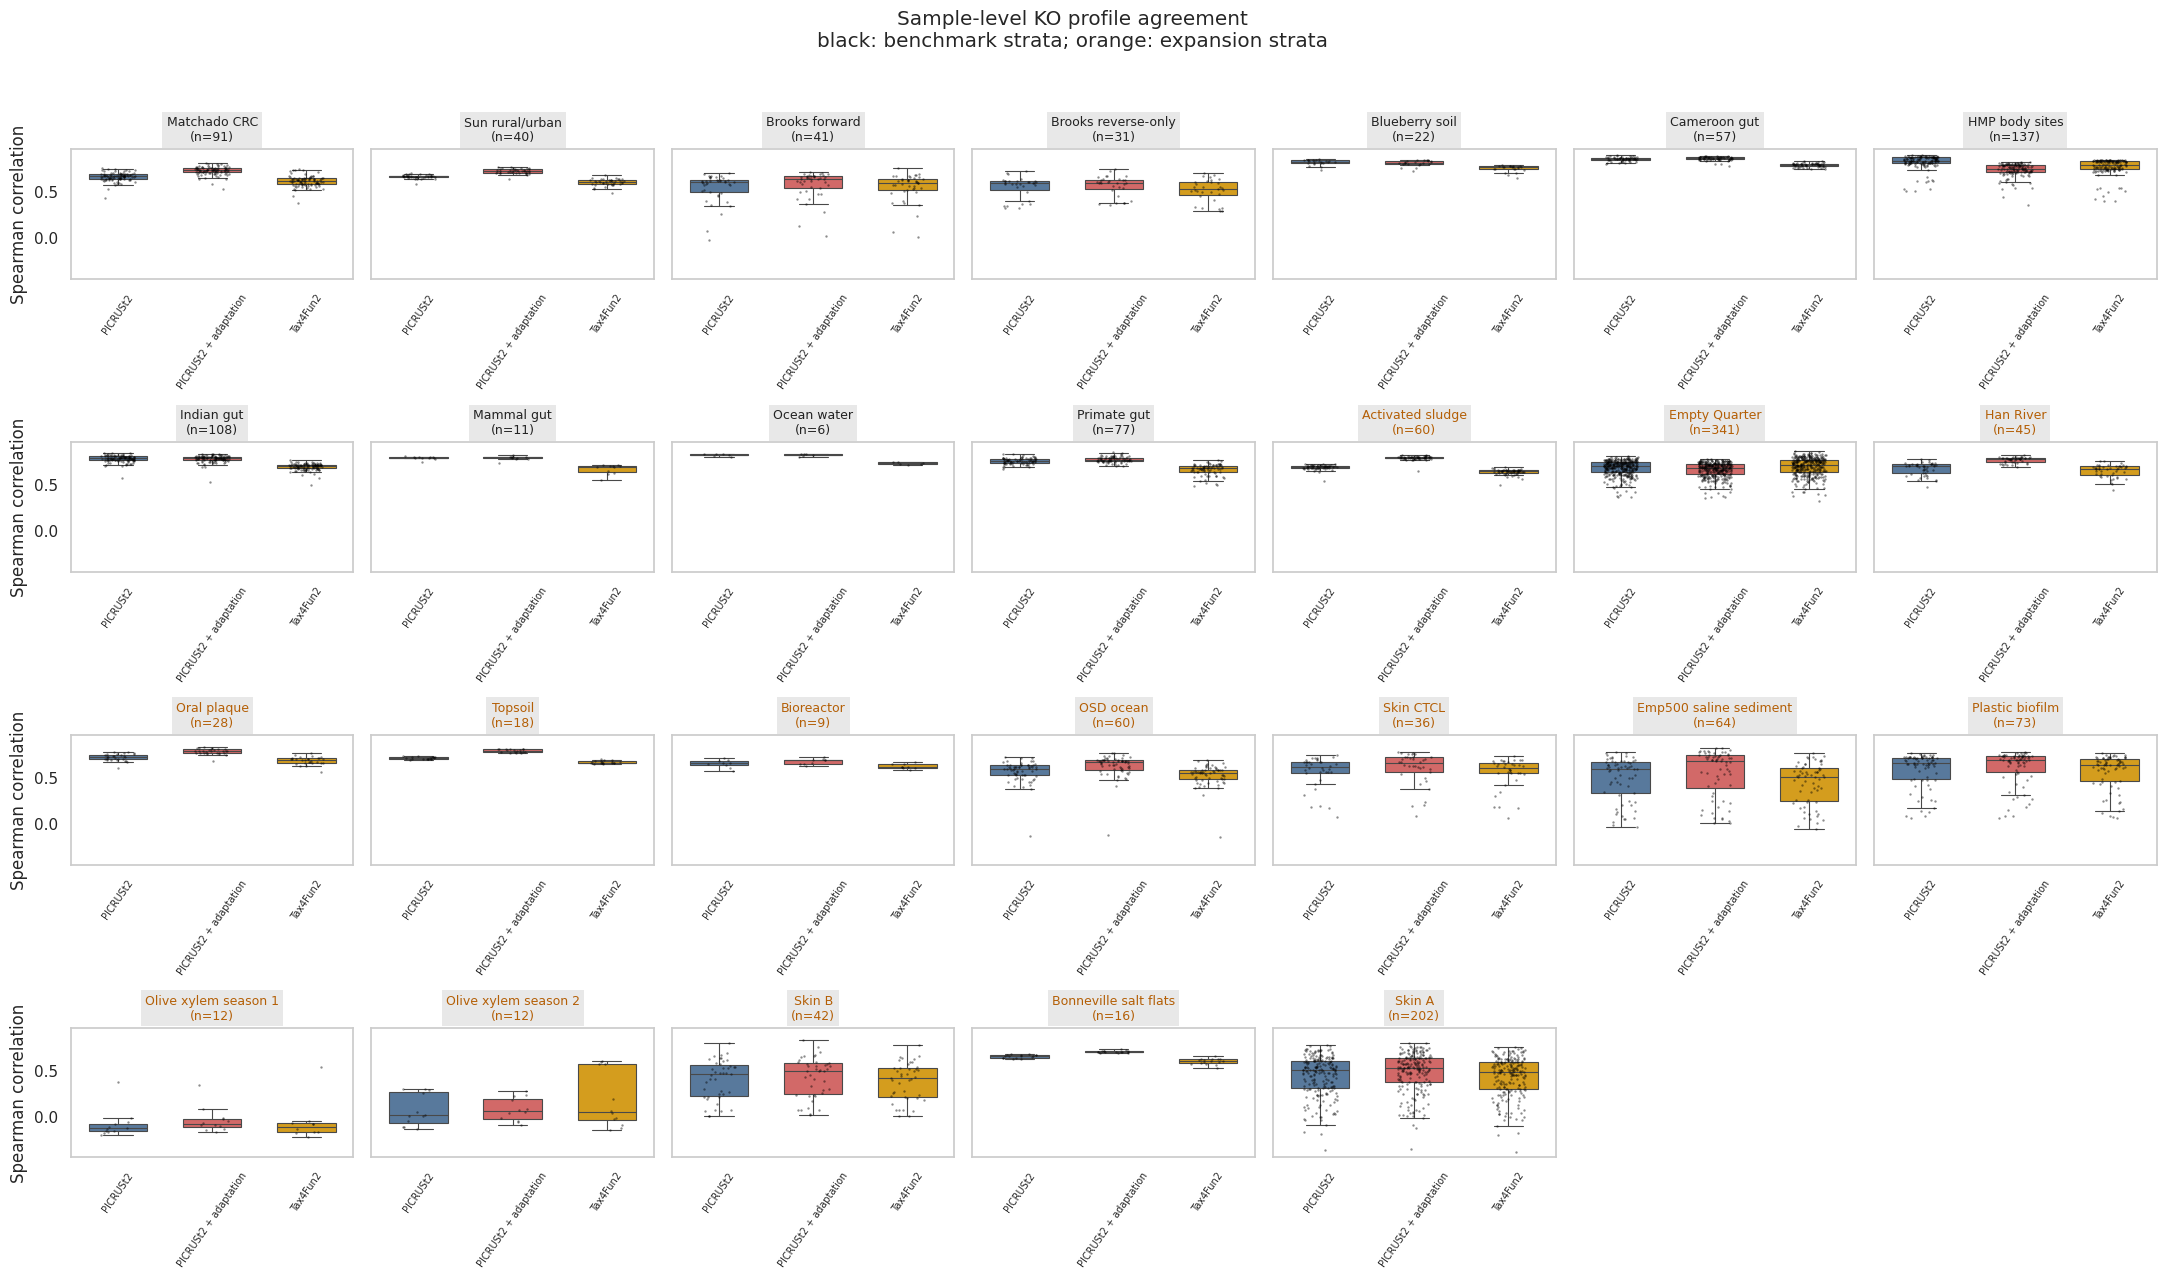

In [5]:
# Plot 1: PICRUSt2-Fig.-2a-style per-study distributions for all three methods.
study_order = registry.dataset.tolist()
fig, axes = plot_profile_study_panels(sample, registry, METHODS, colors=COLORS)

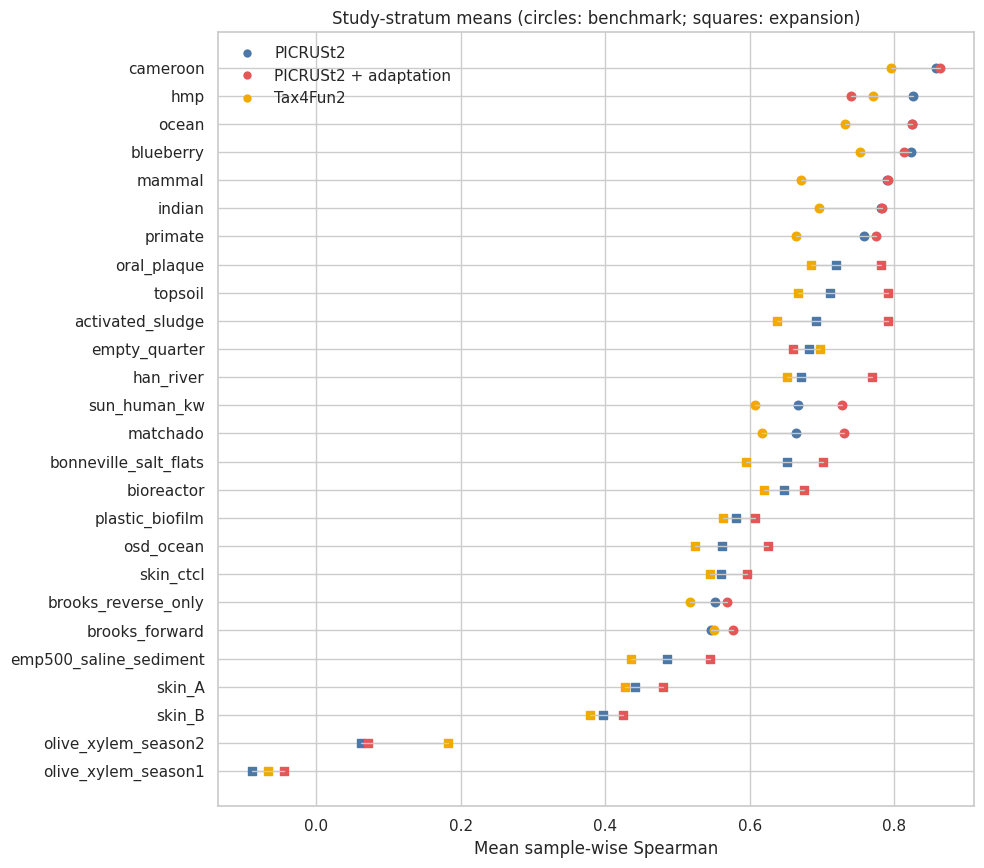

In [6]:
# Plot 2: compact three-method stratum-mean summary.
from matplotlib.lines import Line2D
means = recomputed_strata.merge(registry[["dataset", "is_expansion_group"]], on="dataset", validate="many_to_one")
fig, ax, wide = plot_stratum_mean_ranges(means, METHODS, colors=COLORS)

method_label,PICRUSt2 + adaptation,Tax4Fun2
count,23.000000,23.000000
mean,0.031558,-0.042459
std,0.042122,0.041598
min,-0.086656,-0.119962
25%,0.003051,-0.061380
50%,0.027454,-0.047084
75%,0.061441,-0.018759
max,0.100350,0.082088


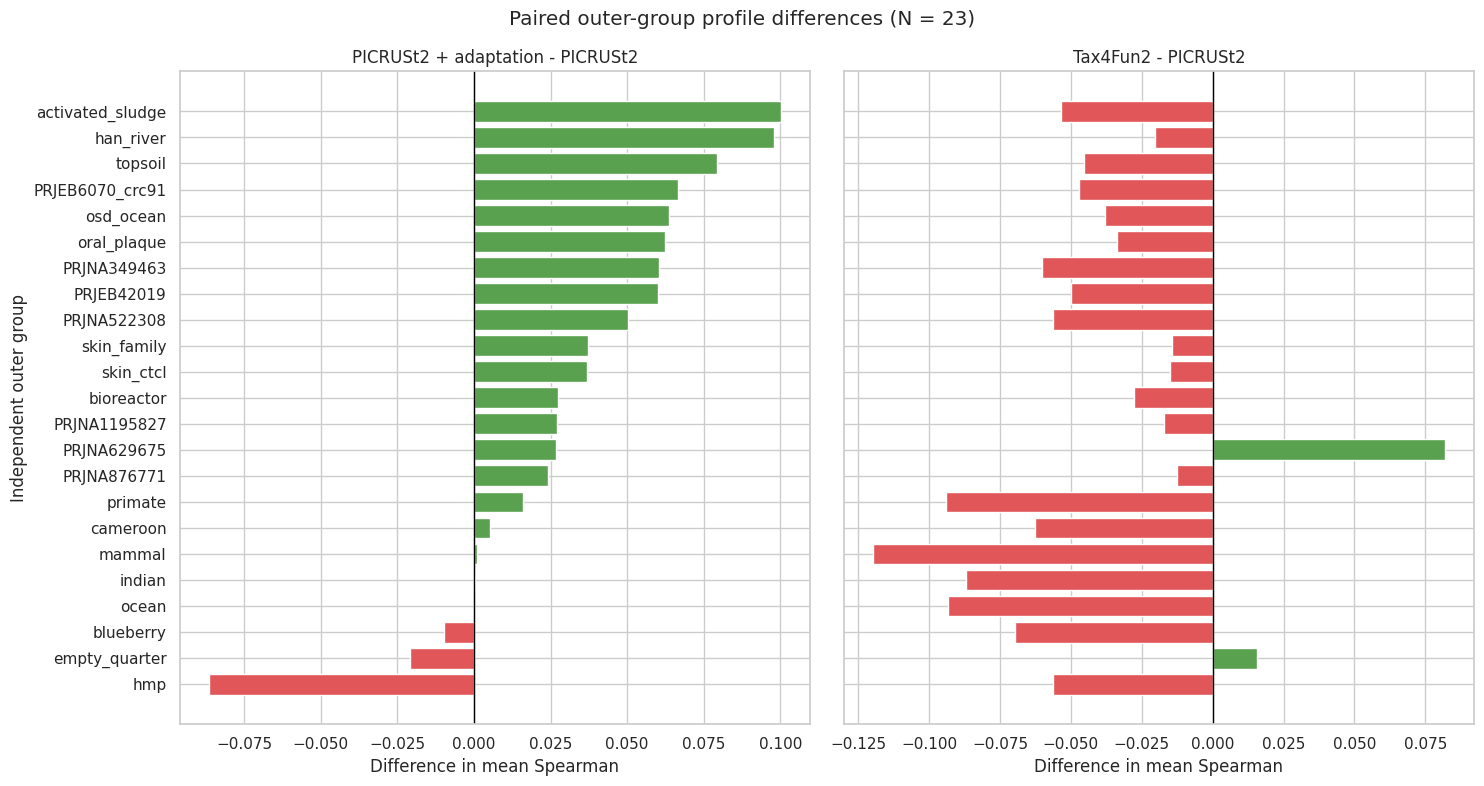

In [7]:
# Plot 3: both alternative methods relative to PICRUSt2 across the 23 outer groups.
group_means = (sample.groupby(["heldout_group", "method_label"], as_index=False)
               .agg(group_mean_sample_spearman=("sample_spearman", "mean")))
fig, axes, gdelta = plot_method_differences(
    group_means, ["PICRUSt2 + adaptation", "Tax4Fun2"], baseline_method="PICRUSt2"
)
display(gdelta.describe())

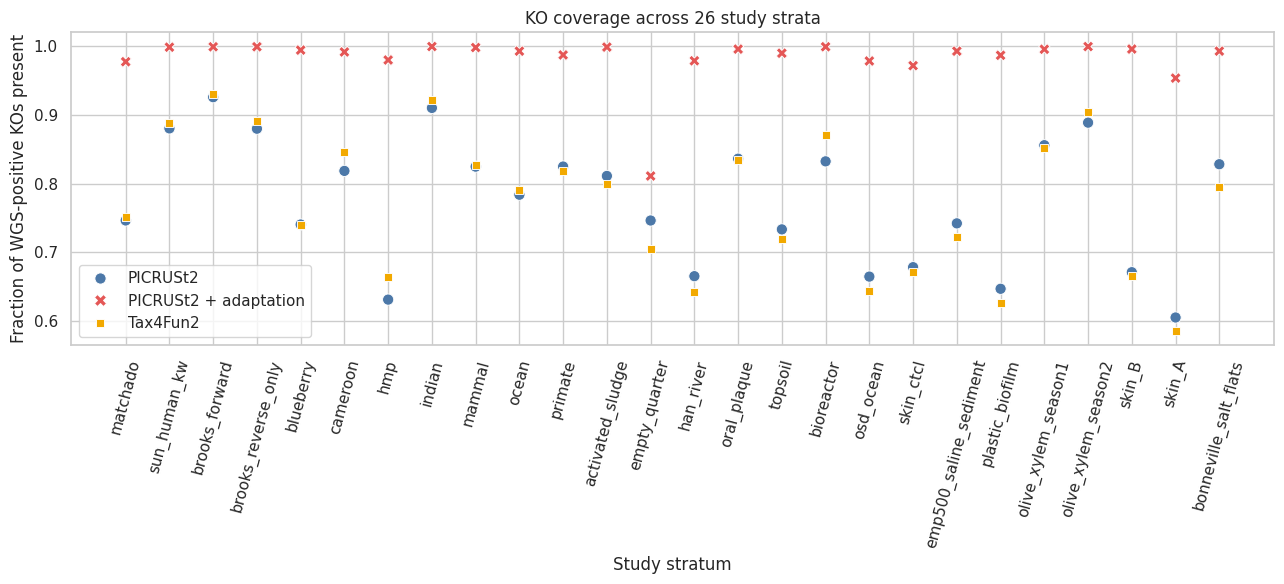

In [8]:
# Plot 4: WGS-universe coverage/zero-fill audit for all three methods.
fig, ax = plot_ko_coverage(coverage, METHODS, colors=COLORS)

## Matchado-style differential-KO recovery

The library implements both (a) the paper-faithful legacy family—shared 5% prevalence, unadjusted
two-sided rank-sum p < 0.05, precision/recall/F1, prediction-label permutations—and (b) the later
project extension using a WGS-only family with BH q < 0.05 and zero-fill. The completed paper-faithful
reference has PICRUSt2 and Tax4Fun2 results for the earlier labeled surface; it predates the basic-MLP
adaptation and the two expansion contrasts, so there is no honest adaptation reference to compare on
that surface. Notebook 02 evaluates the later BH extension for its deliberately fixed two-method scope.

Label-matched legacy Matchado rows: 36; max difference across the non-equivalent earlier KO surface: 0.245


,dataset,prediction_method,metric,estimate_new,permutation_mean,permutation_sd,permutation_min,permutation_max,observed_minus_permutation_mean,n_permutations,...,n_wgs_significant,n_prediction_significant,tp,fp,fn,randomization_method,group_a,group_b,estimate_reference,absolute_error
0,blueberry,PICRUSt2,precision,0.243902,0.229591,0.082883,0.000000,0.357143,0.014311,20,...,1199,41,10,31,1189,matchado_2024_prediction_phenotype_label_permu...,Bulk,Rhizosphere,0.263158,0.019255
1,blueberry,PICRUSt2,recall,0.008340,0.032402,0.051148,0.000000,0.233528,-0.024062,20,...,1199,41,10,31,1189,matchado_2024_prediction_phenotype_label_permu...,Bulk,Rhizosphere,0.012755,0.004415
2,blueberry,PICRUSt2,f1,0.016129,0.049706,0.061288,0.000000,0.271449,-0.033577,20,...,1199,41,10,31,1189,matchado_2024_prediction_phenotype_label_permu...,Bulk,Rhizosphere,0.024331,0.008202
3,blueberry,Tax4Fun2,precision,0.000000,0.226818,0.093358,0.071429,0.366197,-0.226818,20,...,1199,7,0,7,1199,matchado_2024_prediction_phenotype_label_permu...,Bulk,Rhizosphere,0.000000,0.000000
4,blueberry,Tax4Fun2,recall,0.000000,0.045913,0.075769,0.000834,0.307756,-0.045913,20,...,1199,7,0,7,1199,matchado_2024_prediction_phenotype_label_permu...,Bulk,Rhizosphere,0.000000,0.000000
5,blueberry,Tax4Fun2,f1,0.000000,0.062185,0.084439,0.001649,0.305970,-0.062185,20,...,1199,7,0,7,1199,matchado_2024_prediction_phenotype_label_permu...,Bulk,Rhizosphere,0.000000,0.000000
6,cameroon,PICRUSt2,precision,0.583914,0.359710,0.137110,0.127358,0.695015,0.224204,20,...,1788,1579,922,657,866,matchado_2024_prediction_phenotype_label_permu...,Entamoeba positive,Entamoeba negative,0.556250,0.027664
7,cameroon,PICRUSt2,recall,0.515660,0.041443,0.043532,0.005593,0.147092,0.474217,20,...,1788,1579,922,657,866,matchado_2024_prediction_phenotype_label_permu...,Entamoeba positive,Entamoeba negative,0.487671,0.027989
8,cameroon,PICRUSt2,f1,0.547669,0.067331,0.062968,0.010905,0.222640,0.480338,20,...,1788,1579,922,657,866,matchado_2024_prediction_phenotype_label_permu...,Entamoeba positive,Entamoeba negative,0.519708,0.027961
9,cameroon,Tax4Fun2,precision,0.590126,0.339552,0.118974,0.129271,0.657005,0.250574,20,...,1788,871,514,357,1274,matchado_2024_prediction_phenotype_label_permu...,Entamoeba positive,Entamoeba negative,0.494297,0.095830


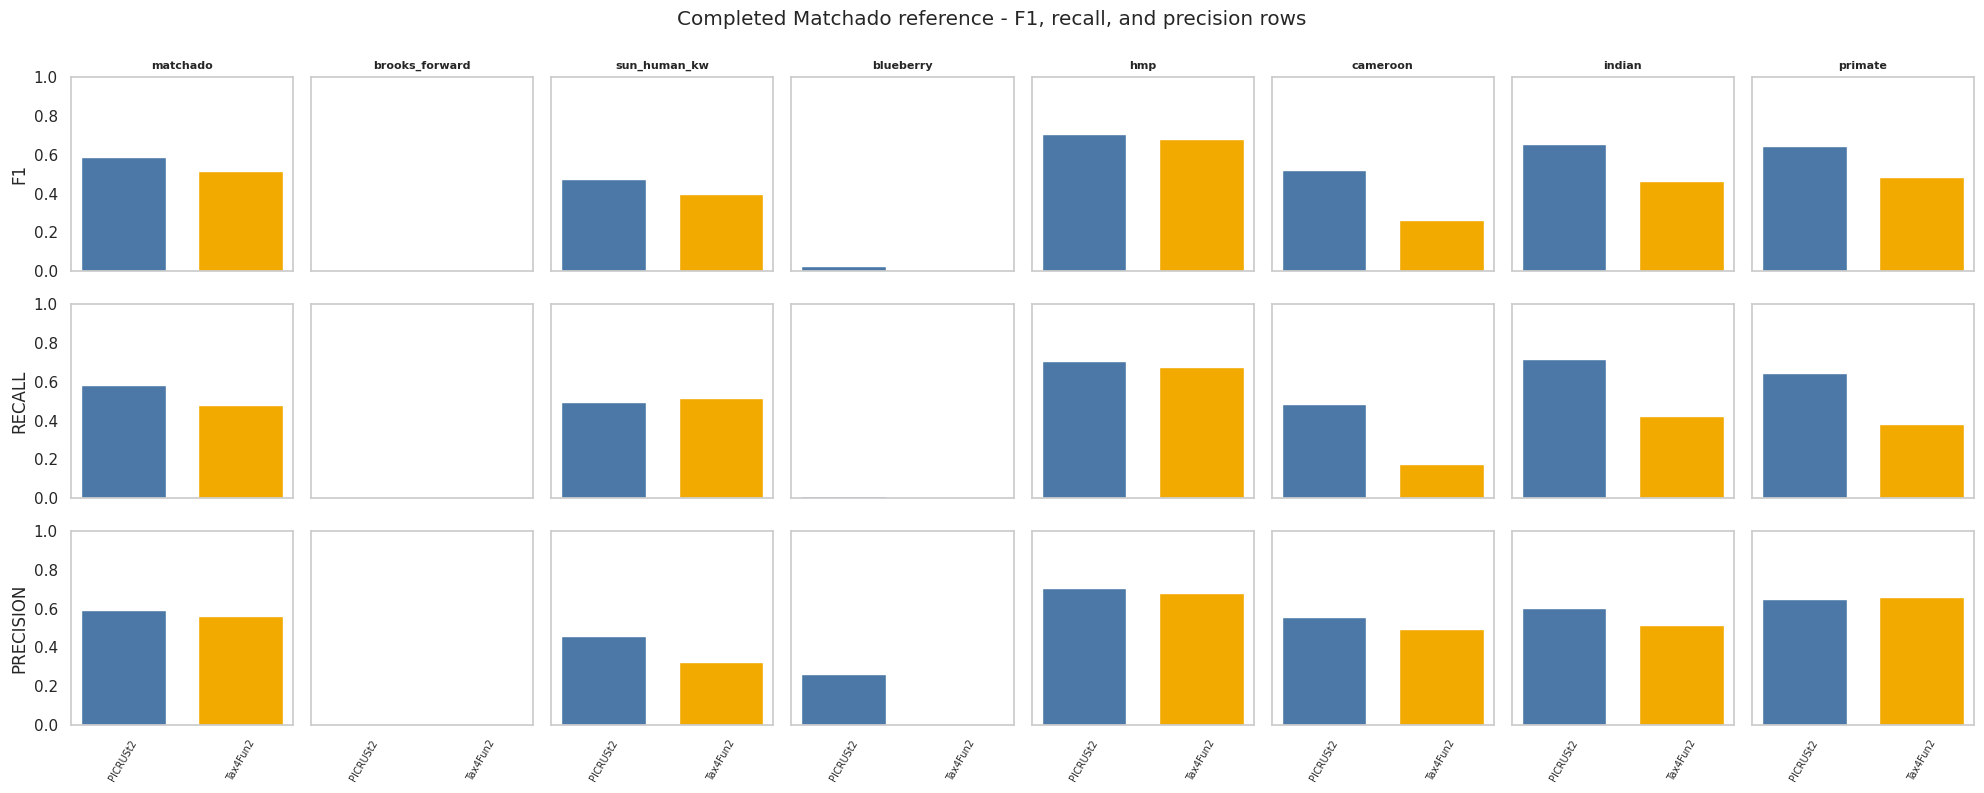

In [9]:
legacy_path = REFERENCE / "matchado_label_metric_results_long.tsv"
legacy = pd.read_csv(legacy_path, sep="\t")
legacy_core = legacy[
    legacy.prediction_method.isin(["PICRUSt2", "Tax4Fun2"]) &
    legacy.metric.isin(["precision", "recall", "f1"]) & legacy.dataset.isin(cohort.dataset)
].copy()
legacy_cmp = published_matchado.merge(
    legacy_core[["dataset", "prediction_method", "metric", "estimate", "group_a", "group_b"]],
    on=["dataset", "prediction_method", "metric", "group_a", "group_b"],
    suffixes=("_new", "_reference"), validate="one_to_one",
)
legacy_cmp["absolute_error"] = (legacy_cmp.estimate_new - legacy_cmp.estimate_reference).abs()
print(f"Label-matched legacy Matchado rows: {len(legacy_cmp)}; "
      f"max difference across the non-equivalent earlier KO surface: {legacy_cmp.absolute_error.max():.3g}")

# Plot 5: completed-reference Matchado rows in the paper's metric-row grammar.
metric_order = ["f1", "recall", "precision"]
legacy_studies = list(dict.fromkeys(legacy_core.dataset))
fig, axes = plot_metric_row_grid(
    legacy_core, legacy_studies, ["PICRUSt2", "Tax4Fun2"], metric_order=metric_order,
    colors=COLORS, title="Completed Matchado reference - F1, recall, and precision rows"
)
display(legacy_cmp)

## Full paper-faithful Matchado and Sun replay

The replay loaded above reads frozen WGS/native/cached-adaptation/Tax4Fun2 matrices and audited labels,
then calls the clean library for every eligible study. Matchado uses its published 20 prediction-label
permutations. Sun uses signed `log10(p)` inference correlation and 100 independent WGS-KO abundance
shuffles with labels fixed. The figures below deliberately reuse each paper's visual grammar.

In [10]:
assert published_matchado.dataset.nunique() == published_sun.dataset.nunique() == 10
assert set(published_matchado.prediction_method) == set(published_sun.prediction_method) == set(METHODS)
display(published_matchado[["dataset", "prediction_method", "metric", "estimate", "permutation_mean"]].head(10))
display(published_sun[["dataset", "prediction_method", "observed_inference_correlation", "randomization_mean"]].head(10))

,dataset,prediction_method,metric,estimate,permutation_mean
0,activated_sludge,PICRUSt2,precision,0.565506,0.586981
1,activated_sludge,PICRUSt2,recall,0.688425,0.042598
2,activated_sludge,PICRUSt2,f1,0.620941,0.074757
3,activated_sludge,PICRUSt2,auroc,0.555539,0.509862
4,activated_sludge,PICRUSt2,aupr,0.606237,0.557670
5,activated_sludge,PICRUSt2 + adaptation,precision,0.569449,0.568955
6,activated_sludge,PICRUSt2 + adaptation,recall,0.649731,0.058984
7,activated_sludge,PICRUSt2 + adaptation,f1,0.606946,0.098258
8,activated_sludge,PICRUSt2 + adaptation,auroc,0.546039,0.504715
9,activated_sludge,PICRUSt2 + adaptation,aupr,0.588529,0.552729


,dataset,prediction_method,observed_inference_correlation,randomization_mean
0,activated_sludge,PICRUSt2,0.389957,0.000901
1,activated_sludge,PICRUSt2 + adaptation,0.310432,0.001328
2,activated_sludge,Tax4Fun2,0.279987,-0.002577
3,blueberry,PICRUSt2,0.083761,-0.002710
4,blueberry,PICRUSt2 + adaptation,0.145844,-0.001693
5,blueberry,Tax4Fun2,0.065118,0.000255
6,brooks_forward,PICRUSt2,0.653745,-0.040227
7,brooks_forward,PICRUSt2 + adaptation,0.614503,-0.041430
8,brooks_forward,Tax4Fun2,0.471672,-0.026906
9,cameroon,PICRUSt2,0.517737,0.002577


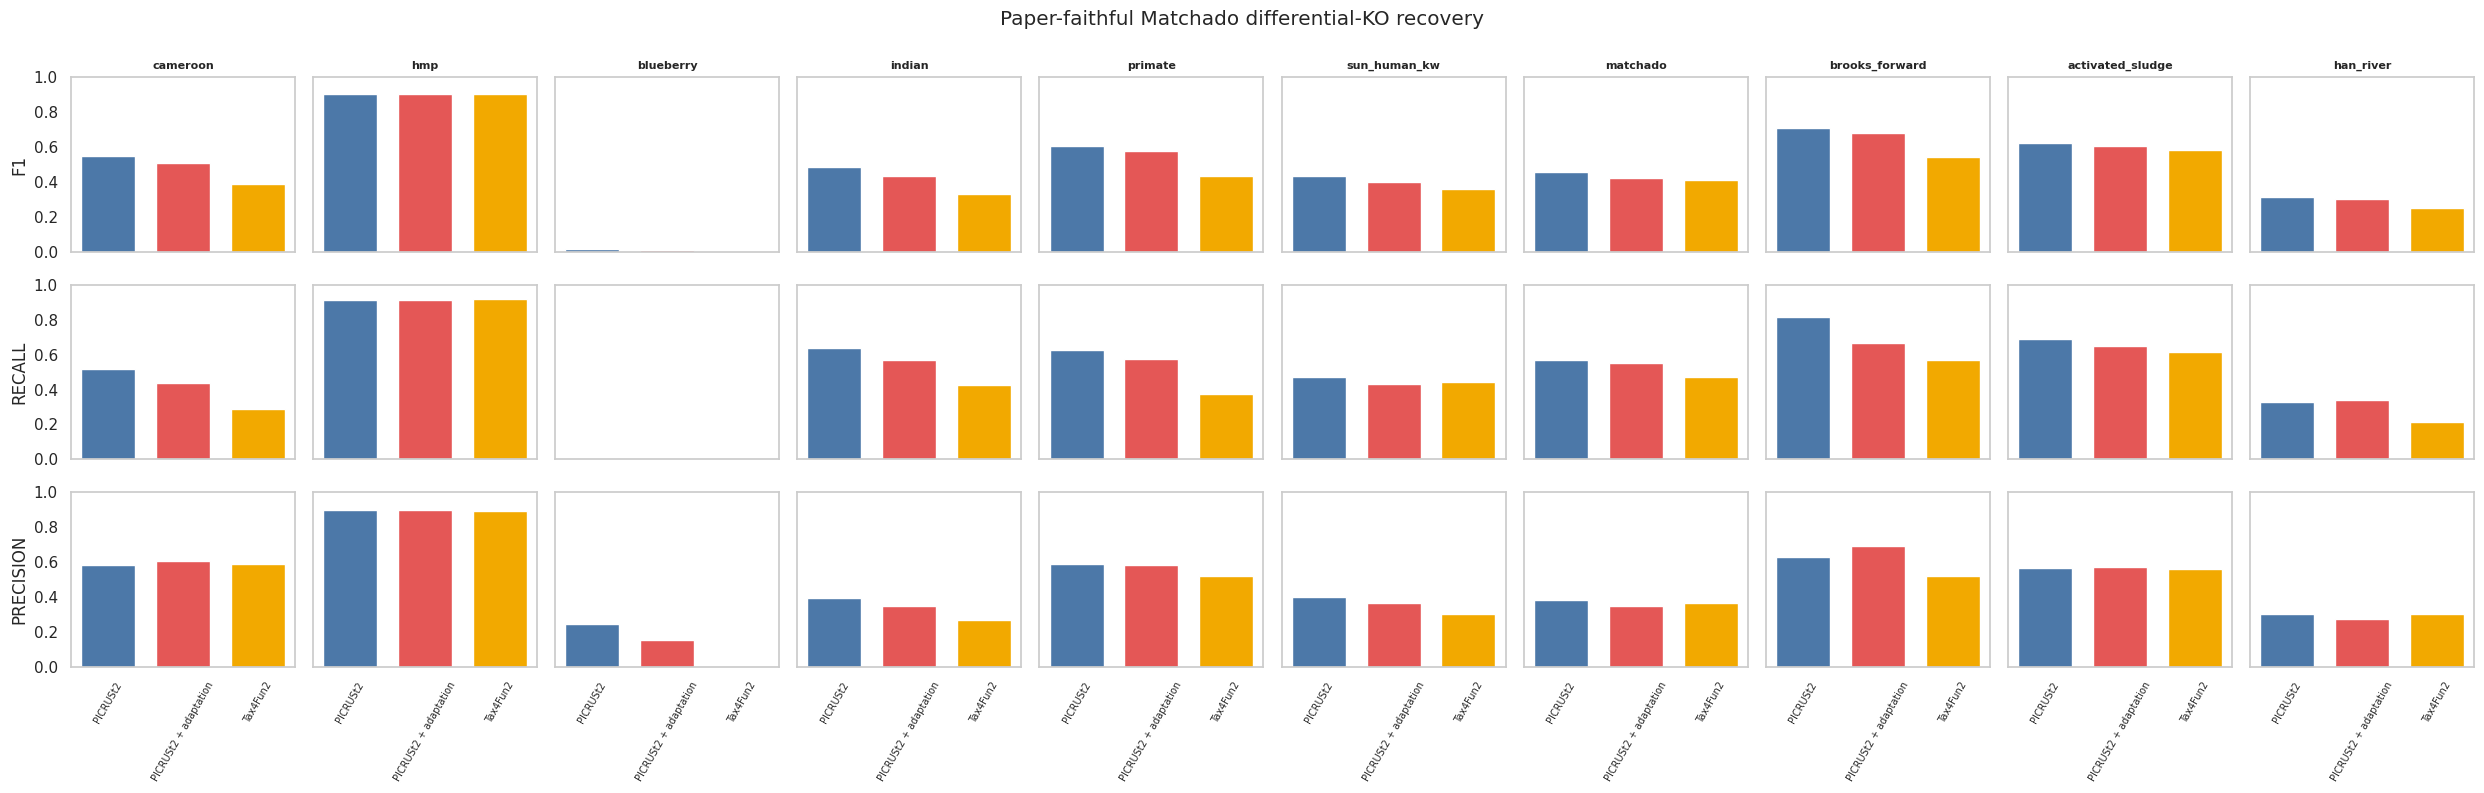

In [11]:
# Plot 6: Matchado-Fig.-6-style set recovery for three methods and all 10 contrasts.
set_metrics = published_matchado[published_matchado.metric.isin(["precision", "recall", "f1"])]
MATCHADO_ORDER = ["cameroon", "hmp", "blueberry", "indian", "primate", "sun_human_kw",
                  "matchado", "brooks_forward", "activated_sludge", "han_river"]
fig, axes = plot_metric_row_grid(
    set_metrics, MATCHADO_ORDER, METHODS, metric_order=["f1", "recall", "precision"],
    colors=COLORS, title="Paper-faithful Matchado differential-KO recovery"
)

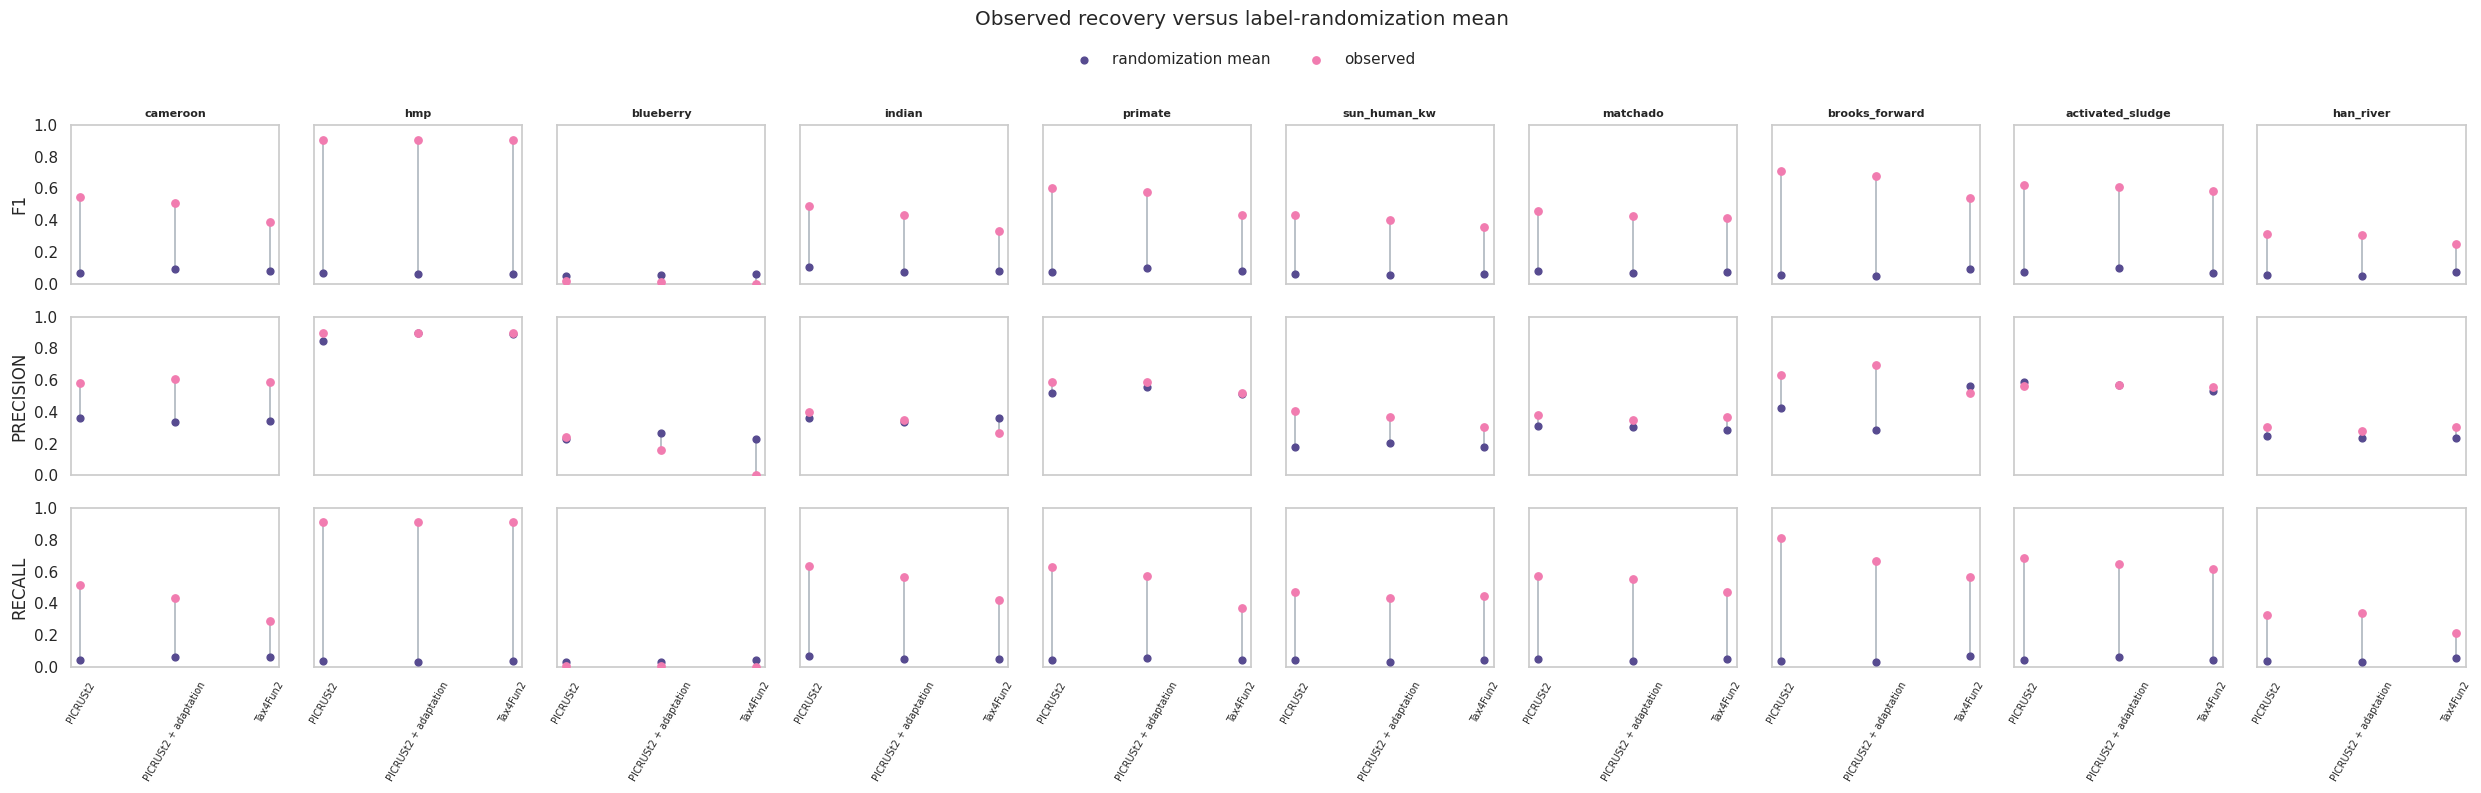

In [12]:
# Plot 7: Matchado-Fig.-7-style observed-versus-randomized dumbbells (lollipops).
fig, axes = plot_matchado_randomization_dumbbells(
    published_matchado, MATCHADO_ORDER, METHODS,
    metric_order=["f1", "precision", "recall"]
)

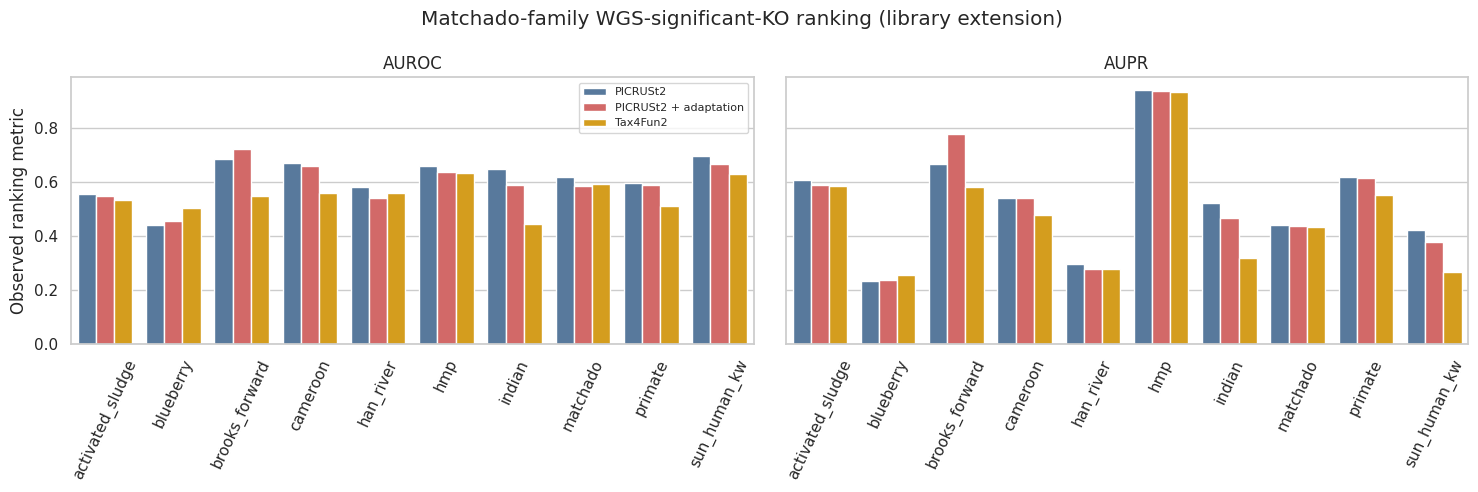

In [13]:
# Plot 8: additional threshold-free ranking metrics returned by the reusable implementation.
ranking_metrics = published_matchado[published_matchado.metric.isin(["auroc", "aupr"])].copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, metric in zip(axes, ["auroc", "aupr"]):
    block = ranking_metrics[ranking_metrics.metric.eq(metric)]
    sns.barplot(data=block, x="dataset", y="estimate", hue="prediction_method",
                hue_order=METHODS, palette=COLORS, ax=ax)
    ax.set(title=metric.upper(), xlabel="", ylabel="Observed ranking metric")
    ax.tick_params(axis="x", rotation=65)
    if ax is axes[1]: ax.legend_.remove()
axes[0].legend(title="", fontsize=8)
fig.suptitle("Matchado-family WGS-significant-KO ranking (library extension)")
fig.tight_layout()

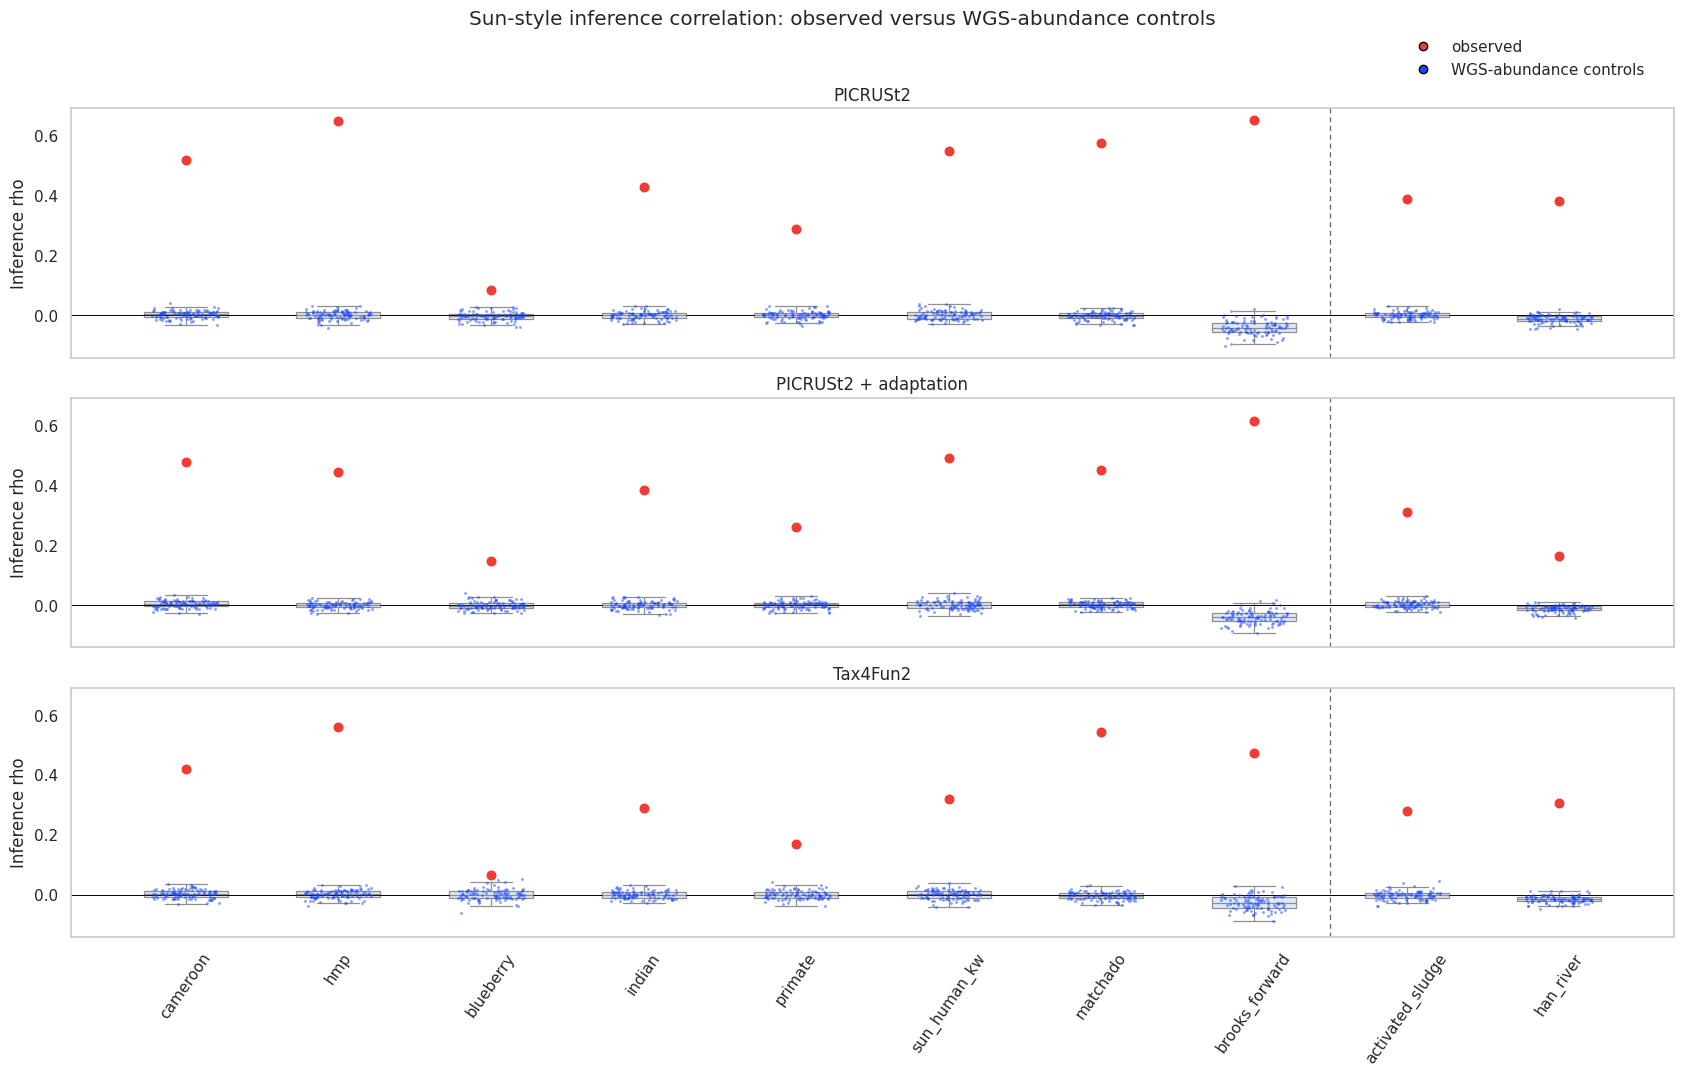

In [14]:
# Plot 9: Sun-Fig.-4-style red observed points over blue 100-randomization controls.
fig, axes = plot_sun_observed_controls(
    published_sun, sun_randomizations, MATCHADO_ORDER, METHODS
)

The raw 10-study Matchado and Sun results above have no completed source table on this exact
three-method/accepted-contrast surface. Their full-surface comparison status is therefore
**unavailable**, not PASS. Directly comparable legacy Matchado rows and the completed 19-study
Tax4Fun2 profile surface are checked where possible.

In [15]:
metric_contract = pd.DataFrame([
    {"family": "KO profile", "studies": 26, "methods": 3, "reference": "accepted two-method table + completed 19-study Tax4Fun2 table", "validation": f"two-method error <=1e-12; Tax4Fun2 max error {tax4fun_cmp.absolute_error.max():.3g} on 1,218 samples"},
    {"family": "Matchado paper-faithful", "studies": 10, "methods": 3, "reference": "completed legacy PICRUSt2/Tax4Fun2 rows where labels match", "validation": f"{len(legacy_cmp)} label-matched rows are surface-non-equivalent (max difference {legacy_cmp.absolute_error.max():.3g}); full three-method reference unavailable"},
    {"family": "Matchado BH extension", "studies": 10, "methods": 2, "reference": "accepted unified5 tables", "validation": "retained in Notebook 02's fixed two-method scope"},
    {"family": "Sun inference correlation", "studies": 10, "methods": 3, "reference": "none on exact accepted surface", "validation": "full 100-randomization replay complete; comparison unavailable"},
])
display(metric_contract)

,family,studies,methods,reference,validation
0,KO profile,26,3,accepted two-method table + completed 19-study...,two-method error <=1e-12; Tax4Fun2 max error 3...
1,Matchado paper-faithful,10,3,completed legacy PICRUSt2/Tax4Fun2 rows where ...,36 label-matched rows are surface-non-equivale...
2,Matchado BH extension,10,2,accepted unified5 tables,retained in Notebook 02's fixed two-method scope
3,Sun inference correlation,10,3,none on exact accepted surface,full 100-randomization replay complete; compar...
